# Lab 14: Automating Data Collection

*INFO 4617/5617 · Week 14 · Chapter 14, [Automating Data Collection](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-14-automation.html)*

This week the lab runs on two days: Monday, November 16 finishes week 13's lab, and this one runs on Wednesday, November 18 and Friday, November 20. Each step says what we're building and why. Its code cells hold a comment saying what to write, and we write the code together. Cells that start with `# Given:` are already written: we read them together and run them. Nothing here is turned in. After each step, a **💬 Discuss** box holds questions to talk over; click it to open it.

One request is a snapshot. A forecast changes every few hours, and so do most of the sources of earlier weeks, so to see how something changes, someone has to ask again and again: a program, on a schedule. Our case is the National Weather Service's hourly forecast for Boulder, which needs no key and no account.
- **Part 1, Wednesday:** one request by hand, then the script that repeats it, `collector.py`. Then you put it in a public repository of your own on GitHub, where GitHub Actions runs it every hour until December 11.
- **Part 2, Friday:** what the course's own collector has gathered since November 13: how often the forecast changed, how the forecast for one hour moved as that hour came closer, whether the collector is still running, and a run you break on purpose.

Along the way, short ⏱ microsprints ask you to change one thing, alone or in pairs, and share what you find.

**Before class:** open this notebook in the `webdata` environment (chapter 1), and have your email address ready for the User-Agent. Sign in to GitHub with the account that holds your project portfolio, and download **`boulder-forecast-template.zip`** from this week's Canvas module. On Friday, start at Step 7, Part 2's setup.

> **Instructor key.** Written on 2026-11-13 from the textbook's plan for chapter 14 (`docs/plans/2026-11-13-ch14-automation.md`, commit 2376f5f on the book's branch `claude/ch14-automation`), before the chapter's rewrite: the chapter on the book's `main` (commit 3036573) is still the earlier version, so the lab links the chapter's page but none of its sections, and "Recommended Exercises ahead" follows the plan. Run on 2026-11-13 at 02:38 UTC (Thursday evening in Boulder) with `labs/tools/run_key.py`: every code cell has output, and none is tagged `not-run-live`. The course's template and series weren't on `main` yet (pull request #186), so for this run the four addresses that read them (`template` in Step 0, `series` in Step 7, and `my_series` in Steps 6 and 10) pointed at that pull request's branch, `claude/week-14-collector`, and were set back to `main` afterwards. The series then held a single run, made by hand at 02:23 UTC, so Part 2's counts are 1 and 1, noon on November 18 has one row, and its plot one point. **Rerun Part 2 (Steps 7–11) once #186 has merged and the course's workflow has run for some days,** best after noon on Wednesday, November 18, when that hour's series is complete, and rewrite the Step 12 answers from its outputs. Steps 6 and 10 read the course's series where students read their own repository's. The GitHub steps (Steps 4 and 5, and Step 11's break and fix) happen in a browser, not in the key: they follow GitHub's documentation as read on 2026-11-13, but weren't clicked through for this key. A rerun of Part 1 will match the grid (BOU 54,75, Boulder), the 156 periods, and the two microsprints' mistypes (404 with `parameterErrors` for the swapped point; 200 for the swapped grid, near Aurora); the forecast, its times and its headers will differ.

# Part 1 — Wednesday, November 18: from one request to a collector that runs every hour

Today we ask the National Weather Service (NWS) for Boulder's hourly forecast, by hand, and read what it says about how new it is. Then we read `collector.py`, the same request written as a script, and put it in a repository of your own, where GitHub runs it every hour. By the end of class, your repository has its first rows.

## Step 0 — Set up (3 minutes)

Put your email address in `HEADERS`, and run the given cell. The NWS asks for no key, but its [documentation](https://www.weather.gov/documentation/services-web-api) (the Overview tab) asks every program for a User-Agent that names it and gives a way to reach whoever runs it, and says a key will replace that one day. `nws_base` is the API's address; `template` is where the course keeps the files that are in the zip.

In [1]:
# Given: Part 1's setup. Put your email address in HEADERS, then run it
import requests
import pandas as pd

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
nws_base = "https://api.weather.gov"
template = "https://raw.githubusercontent.com/cuinfoscience/INFO4617-Fall2026/main/labs/week-14/template/"

<details>
<summary>💬 Discuss</summary>

- In week 11 the Census Bureau and FRED wanted a key; in week 12 Bluesky didn't, and neither does the NWS. What would a key let the NWS do that a User-Agent can't?
- The NWS's forecasts are paid for by taxes and free to use. Who else, besides us, might be asking for Boulder's forecast every hour?
- In the key's tests, a request with an empty User-Agent got 403 and an HTML page, "Access Denied", but one with requests' own User-Agent, `python-requests`, which names no one, got the forecast. If the NWS doesn't check, why send our email?

</details>

## Step 1 — Where is Boulder on the NWS's grid? (9 minutes)

The NWS forecasts for a grid of squares about 2.5 kilometers on a side, each looked after by one of its forecast offices. The [`/points`](https://www.weather.gov/documentation/services-web-api) request takes a latitude and a longitude, in that order, and answers with the office and the square that hold them, and the addresses of their forecasts. When something goes wrong, the NWS answers with JSON whose `detail` says what, so print the status code, then `.get("detail")`: `None` means no error. Then go down the answer one level at a time.

In [2]:
# points_url: f"{nws_base}/points/40.015,-105.2705", latitude first, then longitude (west is negative)
points_url = f"{nws_base}/points/40.015,-105.2705"

In [3]:
# Send it with headers=HEADERS; print the status code and the "Content-Type" header
points_response = requests.get(points_url, headers=HEADERS)
print(points_response.status_code, points_response.headers["Content-Type"])

200 application/geo+json


In [4]:
# points: its .json(); print points.get("detail"): None means there was no error
points = points_response.json()
print(points.get("detail"))

None


In [5]:
# Print the answer's keys; then the keys of its "properties"
print(points.keys())
print(points["properties"].keys())

dict_keys(['@context', 'id', 'type', 'geometry', 'properties'])
dict_keys(['@id', '@type', 'cwa', 'type', 'forecastOffice', 'gridId', 'gridX', 'gridY', 'forecast', 'forecastHourly', 'forecastGridData', 'observationStations', 'relativeLocation', 'forecastZone', 'county', 'fireWeatherZone', 'timeZone', 'radarStation', 'astronomicalData', 'nwr'])


In [6]:
# grid: points["properties"]; print "gridId", "gridX", "gridY", and the "city" in "relativeLocation"'s "properties"
grid = points["properties"]
print(grid["gridId"], grid["gridX"], grid["gridY"])
print(grid["relativeLocation"]["properties"]["city"])

BOU 54 75
Boulder


In [7]:
# hourly_url: grid's "forecastHourly"; print it
hourly_url = grid["forecastHourly"]
print(hourly_url)

https://api.weather.gov/gridpoints/BOU/54,75/forecast/hourly


### ⏱ Microsprint (4 minutes, alone or in pairs)

The likeliest slip in `points_url` is the order of the two numbers.

**Do:** ask `/points` for the same place with the longitude first, `-105.2705,40.015`, under names of your own (`swapped_response`, `swapped`). Print its status code and `detail`, then its `"parameterErrors"`.
**Share:** the status code, and what the NWS said was wrong, in its own words.

In [8]:
# Microsprint: swapped_response: /points with the longitude first; print its status code, "detail" and "parameterErrors"
swapped_response = requests.get(f"{nws_base}/points/-105.2705,40.015", headers=HEADERS)
swapped = swapped_response.json()
print(swapped_response.status_code, swapped.get("detail"))
print(swapped.get("parameterErrors"))

404 Not Found
[{'parameter': 'path.latitude', 'message': 'Must have a minimum value of -90'}]


<details>
<summary>💬 Discuss</summary>

- The documentation says an office and its grid "may occasionally change", and to ask `/points` again from time to time. `collector.py` keeps only the forecast's address. What would it collect if the grid changed?
- With the numbers swapped, the NWS refused the request. Which mistakes in an address would get an error, and which might get a forecast for somewhere else?
- Bluesky's errors in week 12 had a `message`; the NWS's have a `detail`. Why read the error before reading the data?

</details>

## Step 2 — The hourly forecast, and how new it is (9 minutes)

Ask `hourly_url`. Its `properties` hold a list of `periods`, one per hour for about the next six and a half days. Two times say how new it is: `updateTime`, when forecasters last changed the forecast, and `generatedAt`, when the NWS's server built this answer. The response's **headers**, the lines a server sends before its data, say more ([requests' `.headers`](https://requests.readthedocs.io/en/stable/user/quickstart/#response-headers); week 5 printed some). [`Last-Modified`](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/Last-Modified) dates this answer, and [`Cache-Control`](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/Cache-Control) says how long a copy of it may be reused: `max-age` seconds by your browser, `s-maxage` seconds by the NWS's own caches.

In [9]:
# Send hourly_url with HEADERS; print the status code and the "Content-Type" header
hourly_response = requests.get(hourly_url, headers=HEADERS)
print(hourly_response.status_code, hourly_response.headers["Content-Type"])

200 application/geo+json


In [10]:
# hourly: the "properties" of its .json(); print how many "periods" it holds
hourly_json = hourly_response.json()
hourly = hourly_json["properties"]
print(len(hourly["periods"]), "periods")

156 periods


In [11]:
# Print the first period: one hour's forecast
print(hourly["periods"][0])

{'number': 1, 'name': '', 'startTime': '2026-11-12T19:00:00-07:00', 'endTime': '2026-11-12T20:00:00-07:00', 'isDaytime': False, 'temperature': 49, 'temperatureUnit': 'F', 'temperatureTrend': None, 'probabilityOfPrecipitation': {'unitCode': 'wmoUnit:percent', 'value': 0}, 'dewpoint': {'unitCode': 'wmoUnit:degC', 'value': -2.2222222222222223}, 'relativeHumidity': {'unitCode': 'wmoUnit:percent', 'value': 44}, 'windSpeed': '5 mph', 'windDirection': 'W', 'icon': 'https://api.weather.gov/icons/land/night/skc?size=small', 'shortForecast': 'Clear', 'detailedForecast': ''}


In [12]:
# Print its "updateTime" and its "generatedAt"
print("updated:  ", hourly["updateTime"])
print("generated:", hourly["generatedAt"])

updated:   2026-11-12T18:46:17+00:00
generated: 2026-11-13T02:04:16+00:00


In [13]:
# Print the response's "Last-Modified" and "Cache-Control" headers
print("Last-Modified:", hourly_response.headers["Last-Modified"])
print("Cache-Control:", hourly_response.headers["Cache-Control"])

Last-Modified: Fri, 13 Nov 2026 02:00:00 GMT
Cache-Control: public, max-age=1525, s-maxage=3600


### ⏱ Microsprint (3 minutes, alone or in pairs)

**Do:** how old was the forecast when the NWS built your answer? [`pd.to_datetime()`](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html) turns each time into one Python can subtract.
**Share:** your forecast's age, and your neighbor's.

In [14]:
# Microsprint: generated, updated: pd.to_datetime() of "generatedAt" and of "updateTime"; print generated minus updated
generated = pd.to_datetime(hourly["generatedAt"])
updated = pd.to_datetime(hourly["updateTime"])
print(generated - updated)

0 days 07:17:59


<details>
<summary>💬 Discuss</summary>

- In the key's run the forecast was hours older than the answer. If a collector asks every hour, how many of its answers will hold a forecast it already has? (Part 2 counts them.)
- `s-maxage=3600` lets the NWS's caches hand the same answer to everyone for up to an hour. Thirty of us just asked within a minute or two: how many times did the NWS have to build it?
- In the key's tests, a request with [`If-Modified-Since`](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/If-Modified-Since) set to the `Last-Modified` it had been given got 304, Not Modified, with no data. But `Last-Modified` was the top of the hour, when the list moved on by an hour. Would that header save an hourly collector anything?

</details>

## Step 3 — From a notebook to a script (7 minutes)

A collector is the cells above, saved as a script that a computer can run without us: `collector.py`, in the template. Read it together, and find our request in it. Then find four things a notebook didn't need:
- **constants** at the top (`URL`, `HEADERS`, `FILE`, `FIELDS`, `LAST_DAY`), so each is changed in one place;
- a CSV opened to **append** (`"a"`), with its header written only when the file is new ([`csv.DictWriter`](https://docs.python.org/3/library/csv.html#csv.DictWriter));
- [`raise_for_status()`](https://requests.readthedocs.io/en/stable/api/#requests.Response.raise_for_status), which stops the script with an error if the NWS didn't answer 200. Our labs never use it; a script that runs while nobody watches has to fail where someone will see it;
- [`if __name__ == "__main__":`](https://docs.python.org/3/library/__main__.html#idiomatic-usage), which runs `main()` only when the file is run as a script. After December 11, `main()` stops before it asks.

In [15]:
# Given: read the template's collector.py, the file in the zip, and print it
collector = requests.get(template + "collector.py", headers=HEADERS).text
print(collector)

"""Save the National Weather Service's hourly forecast for Boulder, Colorado.

Each run adds one row per forecast hour to forecasts.csv: about 156 rows,
covering the next six and a half days. Run it by hand with
    python collector.py
or on a schedule with the GitHub Actions workflow in .github/workflows/.
"""

import csv
import os
from datetime import date, datetime, timezone

import requests

# The hourly forecast for the 2.5 km grid square over Boulder. Its address
# came from https://api.weather.gov/points/40.015,-105.2705 ("forecastHourly").
URL = "https://api.weather.gov/gridpoints/BOU/54,75/forecast/hourly"

# The NWS asks every program to name itself and give a way to reach its owner.
HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}

# Where the rows go, and the columns each row has, in order.
FILE = "forecasts.csv"
FIELDS = ["collected_at", "update_time", "start_time", "temperature",
          "precip_chance", "wind_speed", "wind_direction", "short_for

<details>
<summary>💬 Discuss</summary>

- Our cells printed what came back and let us read it; the script calls `raise_for_status()` instead. Why does a script that runs on its own need to stop with an error, when a notebook cell didn't?
- What would happen to `forecasts.csv` if the script opened it with `"w"` instead of `"a"`? And if it wrote the header on every run?
- The script stops asking after December 11. Who would keep paying for a collector that nobody reads?

</details>

## Step 4 — Your own repository, with the template in it (12 minutes)

GitHub Actions runs a **workflow**, a file of steps, on GitHub's computers when something happens: here, on a [`schedule`](https://docs.github.com/en/actions/reference/workflows-and-actions/events-that-trigger-workflows#schedule), or when you press a button, [`workflow_dispatch`](https://docs.github.com/en/actions/reference/workflows-and-actions/events-that-trigger-workflows#workflow_dispatch). It runs only the workflows in a repository's `.github/workflows/` folder, and in a public repository it costs nothing ([GitHub's billing page](https://docs.github.com/en/billing/concepts/product-billing/github-actions)). We do it all in the browser, without git. The zip holds that folder, but its name starts with a dot, and macOS hides such names, so it's easy to leave behind when you upload. So we upload two files, and create the workflow on GitHub.

1. **Unzip the template.** Unzip `boulder-forecast-template.zip`, from this week's Canvas module. You'll see `collector.py` and `README.md`. (`.github/workflows/collect.yml` is there too, out of sight on a Mac. We won't use that copy.)
2. **Make a new public repository.** On GitHub, click **+** at the top right, then **New repository** ([GitHub's steps](https://docs.github.com/en/repositories/creating-and-managing-repositories/creating-a-new-repository)). Name it `boulder-forecast`, make it **Public**, and turn on the option to **add a README**, so that the repository starts with a `main` branch. Click **Create repository**.
3. **Upload the two files.** On the repository's page, click **Add file**, then **Upload files** ([GitHub's steps](https://docs.github.com/en/repositories/working-with-files/managing-files/adding-a-file-to-a-repository)), and drag in `collector.py` and `README.md` from the unzipped folder (the template's README replaces GitHub's). Click **Commit changes**. There's no `forecasts.csv` to upload: the first run makes it.
4. **Put your email in `collector.py`.** Click `collector.py`, then the pencil, **Edit this file** ([GitHub's steps](https://docs.github.com/en/repositories/working-with-files/managing-files/editing-files)). In `HEADERS`, change `your-email@colorado.edu` to your own address. Click **Commit changes...**, then **Commit changes**.
5. **Create the workflow.** Back on the repository's page, click **Add file**, then **Create new file** ([GitHub's steps](https://docs.github.com/en/repositories/working-with-files/managing-files/creating-new-files)). In the name box, type `.github/workflows/collect.yml`: each `/` makes a folder. Run the given cell below, copy everything it prints, and paste it into the big box. Click **Commit changes...**, then **Commit changes**.

In [16]:
# Given: print the template's workflow, .github/workflows/collect.yml, to copy into GitHub's new file
workflow = requests.get(template + ".github/workflows/collect.yml", headers=HEADERS).text
print(workflow)

# Run collector.py every hour on GitHub's computers, and commit the new rows.
name: Collect Boulder's hourly forecast

on:
  schedule:
    # Minute 17 of every hour, in UTC. GitHub may start a scheduled run some
    # minutes late, and runs at minute 0 are the most often delayed.
    - cron: "17 * * * *"
  # Adds a "Run workflow" button on the Actions tab, to run it by hand.
  workflow_dispatch:

# The commit step pushes to this repository, so the workflow needs write access.
permissions:
  contents: write

jobs:
  collect:
    runs-on: ubuntu-latest
    steps:
      - name: Get this repository's files
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.12"

      - name: Install requests
        run: pip install requests

      - name: Collect the forecast
        run: python collector.py

      - name: Commit the new rows
        run: |
          git config user.name "github-actions[bot]"
    

<details>
<summary>💬 Discuss</summary>

- Your repository is public, so `forecasts.csv`, and the email in `collector.py`, are public too. What would you keep out of the public repository for your own project, and where does your README say so?
- The workflow's [`permissions`](https://docs.github.com/en/actions/reference/workflows-and-actions/workflow-syntax#permissions) give it `contents: write`, so it can commit to your repository. Why does it need that, and what else could it do with it?
- `cron: "17 * * * *"` means minute 17 of every hour, in UTC. Why not minute 0? (The workflow's comments say.)

</details>

## Step 5 — Run it, and watch (6 minutes)

A schedule's first run can be most of an hour away, and GitHub may start scheduled runs late, so we start the first one by hand.

6. **Start a run.** Click the **Actions** tab. If GitHub asks you to enable workflows, press its button. Click **Collect Boulder's hourly forecast** on the left, then **Run workflow**, keep the branch `main`, and press the green **Run workflow** ([GitHub's steps](https://docs.github.com/en/actions/how-tos/manage-workflow-runs/manually-run-a-workflow)).
7. **Watch the log.** A run appears in the list after a few seconds (refresh the page if not). Click it, then its job, `collect` ([GitHub's steps](https://docs.github.com/en/actions/how-tos/monitor-workflows/use-workflow-run-logs)). Each step of the workflow is a line; click **Collect the forecast** to open it. It prints when it asked, how many hours it saved (about 156), and the forecast's `updateTime`. A green check means every step worked.
8. **See the commit.** Click the **Code** tab. There's a new file, `forecasts.csv`, and the latest commit is by **github-actions[bot]**: "Forecast collected ...". Click the file, and GitHub shows it as a table. From now on the workflow runs by itself, at minute 17 of every hour, until December 11.

<details>
<summary>💬 Discuss</summary>

- Each repository asks the NWS once an hour until December 11: about 550 requests. About how many is that for the whole class, and how many of them will bring a forecast that has changed?
- Keeping each run as a commit is called **git scraping**; newsrooms use it to watch pages that change. What can the commit history show that `forecasts.csv` alone can't?
- In week 7 the Wayback Machine had captured some pages and not others, on days it chose. What does collecting your own series give you that an archive can't, and what does it cost?

</details>

## Step 6 — Read what your collector saved (4 minutes)

GitHub serves each file of a public repository at a **raw** address: the file alone, without GitHub's page around it ([viewing a file's raw content](https://docs.github.com/en/repositories/working-with-files/using-files/viewing-and-understanding-files#viewing-or-copying-the-raw-file-content)). It's `https://raw.githubusercontent.com/`, then your user name, the repository, the branch, and the file. [`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) reads a CSV from an address as well as from a file. The raw copy can be up to five minutes behind the repository, so if yours isn't there yet, wait a minute and run the cell again.

In [17]:
# my_series: "https://raw.githubusercontent.com/<you>/boulder-forecast/main/forecasts.csv", <you> your user name
# The key reads the course's series in place of a student's repository
my_series = "https://raw.githubusercontent.com/cuinfoscience/INFO4617-Fall2026/main/labs/week-14/data/forecasts.csv"

In [18]:
# my_forecasts: pd.read_csv() of my_series; print its shape, and look at its first rows
my_forecasts = pd.read_csv(my_series)
print(my_forecasts.shape)
my_forecasts.head()

(156, 8)


,collected_at,update_time,start_time,temperature,precip_chance,wind_speed,wind_direction,short_forecast
0,2026-11-13T02:23:07+00:00,2026-11-12T18:46:17+00:00,2026-11-12T19:00:00-07:00,49,0,5 mph,W,Clear
1,2026-11-13T02:23:07+00:00,2026-11-12T18:46:17+00:00,2026-11-12T20:00:00-07:00,47,0,6 mph,W,Clear
2,2026-11-13T02:23:07+00:00,2026-11-12T18:46:17+00:00,2026-11-12T21:00:00-07:00,47,0,6 mph,W,Clear
3,2026-11-13T02:23:07+00:00,2026-11-12T18:46:17+00:00,2026-11-12T22:00:00-07:00,45,0,6 mph,W,Mostly Clear
4,2026-11-13T02:23:07+00:00,2026-11-12T18:46:17+00:00,2026-11-12T23:00:00-07:00,46,0,5 mph,W,Mostly Clear


<details>
<summary>💬 Discuss</summary>

- Your file and your neighbor's came from the same address, a few minutes apart. Which columns would differ, and which would be the same?
- If your run had failed, what would this cell have said, and where would you look to find out why?

</details>

## End of Part 1

Your collector now runs every hour, by itself. Before Friday, open your repository's **Actions** tab once: each run is a line, with a green check or a red X. On Friday, Part 2 reads the course's own series, collected the same way every hour since November 13, then checks your own, and breaks a run on purpose. It starts with its own setup step, so you don't need today's cells to have run. Friday's last 15 minutes go to your portfolio checkpoint: see the last cell of this notebook.

# Part 2 — Friday, November 20: what the collector gathered, and how it fails

The course has run the same `collector.py` every hour since November 13, from its own repository. That series is today's starting point: a week of runs, where yours has two days. We count how often the forecast actually changed, follow the forecast for one hour as it came closer, check that the collector is still running, and then break a run on purpose.

## Step 7 — Set up again, and load the course's series (4 minutes)

Part 2 starts fresh, so a student who missed Wednesday can start here. Put your email in `HEADERS`, and run the given cell. Then read the course's series: every row every run has saved, each with the time it was collected. It's today's saved checkpoint, and it's still growing: a new run is added at minute 17 of every hour.

In [19]:
# Given: Part 2's setup. Put your email address in HEADERS, then run it
import requests
import pandas as pd
import matplotlib.pyplot as plt

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
nws_base = "https://api.weather.gov"
# The course's series: the template's collector.py, run every hour since 2026-11-13 by the course's own workflow
series = "https://raw.githubusercontent.com/cuinfoscience/INFO4617-Fall2026/main/labs/week-14/data/forecasts.csv"

In [20]:
# forecasts: pd.read_csv() of series; print its shape, and look at its last rows
forecasts = pd.read_csv(series)
print(forecasts.shape)
forecasts.tail()

(156, 8)


,collected_at,update_time,start_time,temperature,precip_chance,wind_speed,wind_direction,short_forecast
151,2026-11-13T02:23:07+00:00,2026-11-12T18:46:17+00:00,2026-11-19T02:00:00-07:00,37,10,2 mph,W,Partly Cloudy
152,2026-11-13T02:23:07+00:00,2026-11-12T18:46:17+00:00,2026-11-19T03:00:00-07:00,36,10,2 mph,W,Partly Cloudy
153,2026-11-13T02:23:07+00:00,2026-11-12T18:46:17+00:00,2026-11-19T04:00:00-07:00,36,10,1 mph,W,Partly Cloudy
154,2026-11-13T02:23:07+00:00,2026-11-12T18:46:17+00:00,2026-11-19T05:00:00-07:00,36,2,1 mph,W,Partly Cloudy
155,2026-11-13T02:23:07+00:00,2026-11-12T18:46:17+00:00,2026-11-19T06:00:00-07:00,36,2,1 mph,W,Mostly Sunny


<details>
<summary>💬 Discuss</summary>

- The series is a saved copy of what the NWS said each hour. What can it not tell you that a live request to the NWS can, and what can it tell you that a live request can't?
- Every row repeats its run's `collected_at` and `update_time`. Why keep them on every row, rather than once a run?

</details>

## Step 8 — How often did the forecast change? (7 minutes)

Each run is one `collected_at`; each forecast the NWS issued is one `update_time`. [`nunique()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.nunique.html) counts a column's distinct values. If the forecast changed every hour, the two counts would match. Then a given cell lists each forecast with how many runs collected it, and the first and last of them, with [`groupby()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html) and `agg()`: it groups the rows by `update_time`, and works out the three for each group.

In [21]:
# Print how many distinct "collected_at" (runs) and "update_time" (forecasts) the series holds, with .nunique()
print(forecasts["collected_at"].nunique(), "runs")
print(forecasts["update_time"].nunique(), "forecasts")

1 runs
1 forecasts


In [22]:
# Given: for each forecast (update_time), how many runs collected it, and the first and last run that did
per_forecast = forecasts.groupby("update_time")["collected_at"].agg(["nunique", "min", "max"])
print(per_forecast.to_string())

                           nunique                        min                        max
update_time                                                                             
2026-11-12T18:46:17+00:00        1  2026-11-13T02:23:07+00:00  2026-11-13T02:23:07+00:00


### ⏱ Microsprint (3 minutes, alone or in pairs)

**Do:** divide the number of forecasts by the number of runs: the share of runs that brought a forecast no earlier run had.
**Share:** the share; then, if 30 collectors each ask 24 times a day, how many of their 720 daily requests bring a new forecast?

In [23]:
# Microsprint: new_share: update_time's .nunique() divided by collected_at's; print it, then 720 times it, both rounded
new_share = forecasts["update_time"].nunique() / forecasts["collected_at"].nunique()
print(round(new_share, 2))
print(round(720 * new_share), "of 720 daily requests")

1.0
720 of 720 daily requests


<details>
<summary>💬 Discuss</summary>

- Each run asked for the whole six and a half days, about 156 hours, even when nothing had changed. Who pays for the requests that bring nothing new: the NWS, GitHub, or us?
- How could a collector ask less often and still miss nothing? What would it need to know about when the NWS updates its forecasts?
- Some forecasts were collected by many runs, some by few. What does that say about when the forecasters update it?

</details>

## Step 9 — One hour's forecast, as it came closer (9 minutes)

Each run forecasts every hour of the next six and a half days, so a single hour is forecast again by every run, up to about 156 times, before it comes. Take one: noon on Wednesday, November 18, our first class. Its **lead time** in each run is how far ahead the forecast was made: the hour's `start_time` minus the run's `collected_at`. A given cell works it out in hours, with [`.dt.total_seconds()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.total_seconds.html), and plots the forecast temperature against it: far ahead on the left, the hour itself on the right.

In [24]:
# noon_rows: the rows whose "start_time" is "2026-11-18T12:00:00-07:00"; print how many
noon_rows = forecasts[forecasts["start_time"] == "2026-11-18T12:00:00-07:00"]
print(len(noon_rows))

1


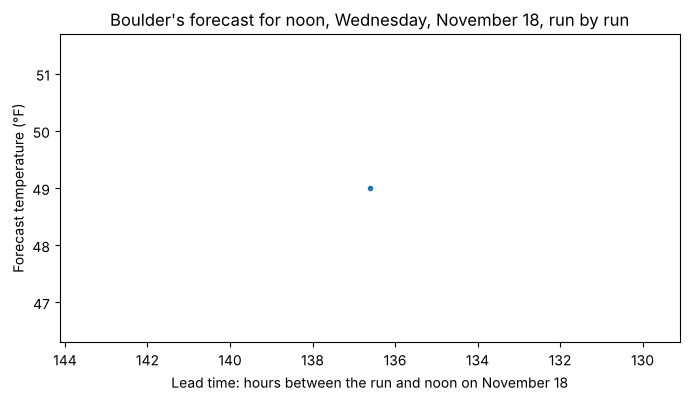

In [25]:
# Given: each row's lead time in hours (start_time minus collected_at); plot the forecast temperature against it
lead = pd.to_datetime(noon_rows["start_time"], utc=True) - pd.to_datetime(noon_rows["collected_at"], utc=True)
lead_hours = lead.dt.total_seconds() / 3600
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lead_hours, noon_rows["temperature"], marker=".")
ax.invert_xaxis()
ax.set_title("Boulder's forecast for noon, Wednesday, November 18, run by run")
ax.set_xlabel("Lead time: hours between the run and noon on November 18")
ax.set_ylabel("Forecast temperature (°F)")
plt.show()

In [26]:
# Print noon_rows' first and last "collected_at", "temperature" and "short_forecast": furthest ahead, and nearest
print(noon_rows[["collected_at", "temperature", "short_forecast"]].head(1))
print(noon_rows[["collected_at", "temperature", "short_forecast"]].tail(1))

                  collected_at  temperature       short_forecast
137  2026-11-13T02:23:07+00:00           49  Chance Rain Showers
                  collected_at  temperature       short_forecast
137  2026-11-13T02:23:07+00:00           49  Chance Rain Showers


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** do the same for midnight that night, `2026-11-19T00:00:00-07:00`, under a name of your own (`midnight_rows`). Print how many runs forecast it, and its lowest and highest forecast temperature.
**Share:** how far apart the lowest and highest were, beside noon's.

In [27]:
# Microsprint: midnight_rows: the rows for "2026-11-19T00:00:00-07:00"; print how many, and the lowest and highest "temperature"
midnight_rows = forecasts[forecasts["start_time"] == "2026-11-19T00:00:00-07:00"]
print(len(midnight_rows))
print(midnight_rows["temperature"].min(), midnight_rows["temperature"].max())

1
39 39


<details>
<summary>💬 Discuss</summary>

- Which of these forecasts was right? The file can't say: what else would you have to collect to know, and from where?
- A forecast made five days ahead and one made an hour ahead are both "the NWS's forecast for noon". When you cite a forecast, what has to come with it?
- In week 10 a Wikipedia article had a history of versions, each kept by Wikipedia. Who keeps the history of a forecast, if not us?

</details>

## Step 10 — Is it still running? A freshness check (6 minutes)

A collector that stops doesn't say so: its file just stops growing. A **freshness check** asks how old the newest row is. [`pd.Timestamp.now(tz="UTC")`](https://pandas.pydata.org/docs/reference/api/pandas.Timestamp.now.html) is the time now, in UTC, like `collected_at`. Runs are an hour apart, GitHub can start one late, and the raw copy can be five minutes behind, so a newest row less than about an hour and a half old is fresh. Check the course's series, then your own. Then check the forecast itself: rows can keep coming while `update_time` stands still.

In [28]:
# newest: the latest "collected_at", as a time (pd.to_datetime(), then .max()); print it, and how long ago it was
newest = pd.to_datetime(forecasts["collected_at"]).max()
print(newest, pd.Timestamp.now(tz="UTC") - newest)

2026-11-13 02:23:07+00:00 0 days 00:15:49.337396


In [29]:
# my_series: your raw address, as on Wednesday; my_newest: the latest "collected_at" of its CSV; print it, and its age
# The key reads the course's series in place of a student's repository
my_series = "https://raw.githubusercontent.com/cuinfoscience/INFO4617-Fall2026/main/labs/week-14/data/forecasts.csv"
my_newest = pd.to_datetime(pd.read_csv(my_series)["collected_at"]).max()
print(my_newest, pd.Timestamp.now(tz="UTC") - my_newest)

2026-11-13 02:23:07+00:00 0 days 00:15:49.563625


In [30]:
# The forecast can be stale too: print how long ago the course series' newest "update_time" was
print(pd.Timestamp.now(tz="UTC") - pd.to_datetime(forecasts["update_time"]).max())

0 days 07:52:39.570595


<details>
<summary>💬 Discuss</summary>

- This check works only when someone runs it. Where could it run so that it warns you without your asking?
- Which failures would it catch that a red X wouldn't? Think of a schedule that GitHub pauses, or an NWS that keeps sending the same old forecast.

</details>

## Step 11 — Break a run on purpose, and fix it (7 minutes)

A run fails loudly when the script raises an error: GitHub marks it with a red X, and can tell whoever created the workflow ([notifications for workflow runs](https://docs.github.com/en/actions/concepts/workflows-and-actions/notifications-for-workflow-runs)). First see, here, what the NWS says to a mistyped address. Then break your collector the same way:

1. **Break it.** In your repository, open `collector.py`, click the pencil, and in `URL` change `hourly` to `hourlyy`. Commit the change.
2. **Run it.** On the **Actions** tab, run the workflow as on Wednesday. Wait for the red X; open the run, then the job. The failed step, **Collect the forecast**, opens by itself. Near its end is the error `raise_for_status()` raised: `requests.exceptions.HTTPError: 404 Client Error: Not Found for url: ...`. The commit step was skipped, so no rows were added.
3. **Fix it.** Change `hourlyy` back to `hourly`, commit, and run the workflow again, for a green check.

In [31]:
# broken_url: f"{nws_base}/gridpoints/BOU/54,75/forecast/hourlyy"; send it, and print the status code and "detail"
broken_url = f"{nws_base}/gridpoints/BOU/54,75/forecast/hourlyy"
broken_response = requests.get(broken_url, headers=HEADERS)
broken = broken_response.json()
print(broken_response.status_code, broken.get("detail"))

404 '/gridpoints/BOU/54,75/forecast/hourlyy' is not a valid resource path


### ⏱ Microsprint (3 minutes, alone or in pairs)

Not every mistype fails.

**Do:** ask for the hourly forecast with the grid numbers swapped, `75,54`, under names of your own. Print its status code, and its first period's temperature.
**Share:** the status code, and whether anything told you it wasn't Boulder.

In [32]:
# Microsprint: the hourly forecast for "BOU/75,54"; print the status code and its first period's "temperature"
swapped_grid_url = f"{nws_base}/gridpoints/BOU/75,54/forecast/hourly"
swapped_grid_response = requests.get(swapped_grid_url, headers=HEADERS)
swapped_grid = swapped_grid_response.json()["properties"]
print(swapped_grid_response.status_code, swapped_grid["periods"][0]["temperature"])

200 50


<details>
<summary>💬 Discuss</summary>

- In the key's tests, `75,54` is a square near Aurora, and `BOX` for `BOU` a square in Rhode Island: both answered 200, with a forecast. Would `raise_for_status()` have stopped either? What check in `collector.py` could?
- None of our cells handle errors: a 429 or a 503 from the NWS would stop a cell at `.json()` or at its first `["properties"]`. In `collector.py`, which line would stop instead, and what would the workflow do next hour?
- Which would you rather find in your data a month from now: a gap, or a month of Aurora's forecasts?

</details>

## Step 12 — What did we learn? (2 minutes)

In a few sentences, as comments:

- How many runs did the course's series hold, and how many distinct forecasts? What does that say about how often a collector should ask?
- How far did the forecast for noon on November 18 move as it came closer?
- Name one failure your collector would show with a red X, and one it wouldn't.
- What should your own project's README say so that someone could tell, a year from now, when and how your data were collected?

**Recommended Exercises ahead** (in the [chapter's](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-14-automation.html) companion notebook, due Sunday, November 22):

- Another NWS grid point, or another NWS product, by hand: Steps 1 and 2, `/points` and then the address it gives.
- A freshness check: Step 10's age of the newest `collected_at`, and of the newest `update_time`.
- A workflow of your own: Steps 3–5, `collector.py` and `collect.yml`, and Step 11's red X and its log.

In [33]:
# Your answers here, as comments
# 1. In the key's run (2026-11-13) the series held 1 run and 1 forecast, too few to say: rerun Part 2. Part 1 showed
#    why the counts will differ: the forecast was 7 hours 18 minutes old when the NWS built our answer, so most hourly
#    runs save a forecast the file already has. Ask less often, or keep only runs whose update_time is new.
# 2. Too soon to say in the key's run: noon on November 18 had one row, 49°F and "Chance Rain Showers", forecast about
#    five days ahead. Rerun once the course's series has a week of runs.
# 3. A red X: a mistyped address, which the NWS answers 404 ("not a valid resource path") and raise_for_status()
#    turns into an HTTPError. No red X: the grid numbers swapped, which answered 200 with a forecast near Aurora;
#    an update_time that stops changing; or a schedule GitHub pauses, which leaves no run at all.
# 4. When it ran (collected_at, and the commit history), what the source said about its own freshness (update_time),
#    the address and the code that asked, when collection stopped, and that a rerun today can't recover past forecasts.

## Friday, November 20: your portfolio checkpoint (15 minutes)

Friday's last 15 minutes, after Part 2, go to your project. This week's checkpoint, **Draft your write-up**, is due after Fall Break, on Sunday, November 29:

- **A full draft of your written document**, `report.md` or `report.pdf`, with every section present, using your own results and figures, and citing your sources;
- **all four required files present and current:** `README.md`, `proposal.md`, your notebook, and your report;
- **a README complete enough that someone else could reproduce the project:** setup, how to run it, and where the data came from.

Use the time on the README's "How to reproduce" section, here, where you can ask: if your data came from requests, say when you sent them, from what code, and what a rerun today would get that yours didn't. Your final presentation is in the week after Fall Break, and the final repository and write-up are due Monday, December 7.

The lab's Recommended Exercises are due Sunday, November 22.